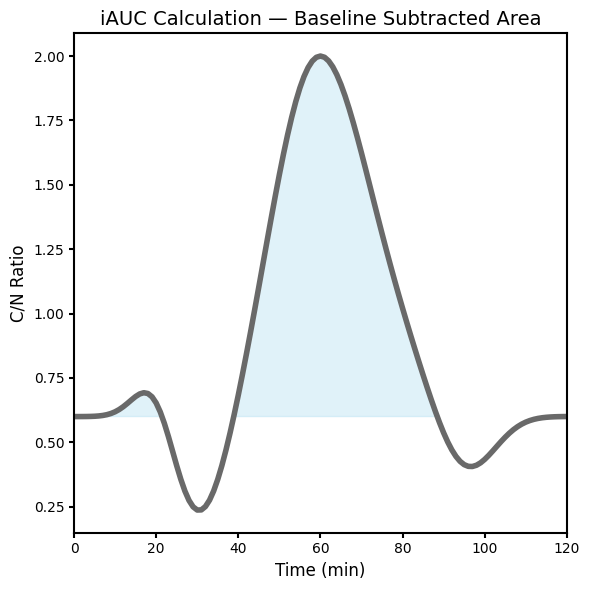

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

OUTFILE = "SAMPLE TRACE"   # .png and .pdf written

# Figure — iAUC explainer using real ERK trace
t_erk = np.arange(121)  # 150 min

# Gamma pulse peaking at t
signal = 1.4 * ((t_erk / 60) * np.exp(1 - t_erk / 60)) ** 25

# Small curved deviations flanking the main peak
pre_bump  =  .2 * np.exp(-((t_erk - 20) / 7)  ** 2)   # gentle rise before
pre_dip = -0.4 * np.exp(-((t_erk - 30) / 10) ** 2)   # gentle dip before
post_bump = -0.25 * np.exp(-((t_erk - 95) / 10) ** 2)   # gentle dip after
signal = signal + pre_bump + pre_dip + post_bump

# Realistic baseline (~0.60), no noise → perfectly smooth
baseline_val = 0.60
raw_trace = baseline_val + signal

t_real   = np.arange(len(raw_trace))
baseline = float(np.mean(raw_trace[:3]))
above    = np.maximum(0.0, raw_trace - baseline)
iauc_val = float(np.sum(above))

# --- Duration / FWHM metrics ---
peak_idx   = int(np.argmax(raw_trace))
peak_amp   = raw_trace[peak_idx]
half_max   = baseline + (peak_amp - baseline) * 0.5

# Half-max crossings
left_idx  = np.where((t_real <= peak_idx) & (raw_trace <= half_max))[0][-1]
right_idx = np.where((t_real >= peak_idx) & (raw_trace <= half_max))[0][0]

fig, ax = plt.subplots(figsize=(6, 6))

ax.fill_between(t_real, baseline, raw_trace,
                where=(raw_trace > baseline),
                color='skyblue', alpha=0.25)
# ax.fill_between(t_real, baseline, raw_trace,
#                 where=(raw_trace < baseline),
#                 color='salmon', alpha=0.25)

ax.plot(t_real, raw_trace, color='dimgray', lw=4, zorder=2)

# --- Metric lines: solid, each a distinct color ---
# Baseline
# ax.axhline(baseline, color='#1b9e77', lw=4, ls='-', zorder=3,
#            label='Baseline')
# # Peak amplitude: baseline → peak apex (vertical)
# ax.plot([peak_idx, peak_idx], [baseline, peak_amp],
#         color='#d95f02', lw=4, ls='-', zorder=4,
#         label='Peak amplitude')
# # FWHM: half-max width (horizontal)
# ax.plot([left_idx, right_idx], [half_max, half_max],
#         color='#7570b3', lw=4, ls='-', zorder=4,
#         label='FWHM (duration)')
# # Time to first peak: t=0 → peak time (horizontal)
# ttp_y = baseline + (peak_amp - baseline) * 0.85
# ax.plot([0, peak_idx], [ttp_y, ttp_y],
#         color='#e7298a', lw=4, ls='-', zorder=4,
#         label=f'Time to peak ({peak_idx} min)')

LABEL_FS = 12

def style_ax(ax):
    for s in ax.spines.values():
        s.set_linewidth(1.5)
    ax.tick_params(width=1.5)

ax.set_xlabel('Time (min)', fontsize=LABEL_FS)
ax.set_ylabel('C/N Ratio', fontsize=LABEL_FS)
ax.set_title('iAUC Calculation — Baseline Subtracted Area', fontsize=14)
ax.set_xlim(0, len(raw_trace) - 1)
#ax.grid(True, alpha=0.25)
#ax.legend(loc='upper right', fontsize=10, framealpha=0.9)

fig.savefig(f"{OUTFILE}.pdf", bbox_inches="tight")   # vector, for further editing

style_ax(ax)
plt.tight_layout()
plt.show()

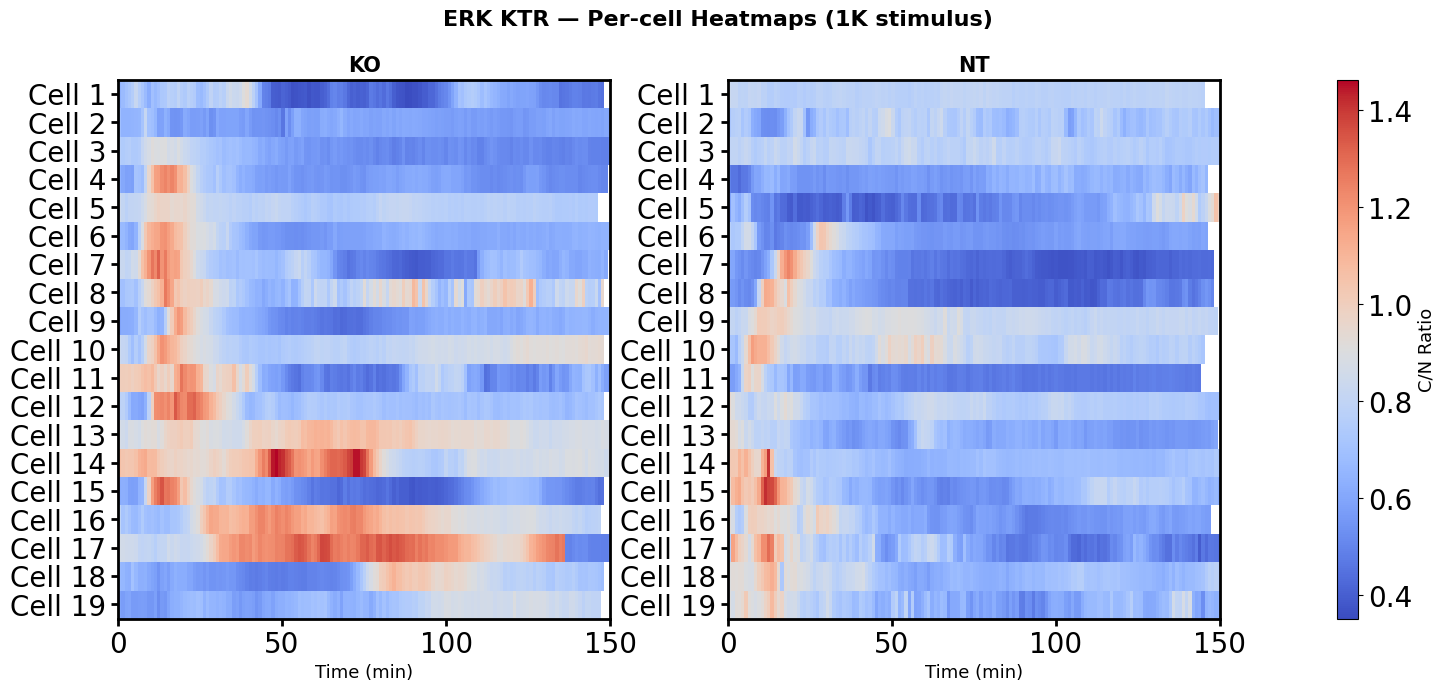

In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

LABEL_FS = 13
TICK_FS  = 20
SPINE_LW = 2.0
TICK_LW  = 2.0
TICK_LEN = 5

def style_ax(ax):
    for spine in ax.spines.values():
        spine.set_linewidth(SPINE_LW)
    ax.tick_params(axis='both', which='major',
                   width=TICK_LW, length=TICK_LEN, labelsize=TICK_FS)

# --- Load raw data, no smoothing ---
df = pd.read_csv('1K.csv', header=None)
raw_conditions = df.iloc[0].tolist()
data = df.iloc[1:].astype(float).values
conditions = [str(c).split('.')[0].strip() for c in raw_conditions]

def get_group_matrix(conditions, data, group):
    idxs = [i for i, c in enumerate(conditions) if c == group]
    return np.array([data[:, i].astype(float) for i in idxs])

ko_mat = get_group_matrix(conditions, data, 'KO')
nt_mat = get_group_matrix(conditions, data, 'NT')

# --- Manual row orders (1-indexed cell IDs) ---
ko_order_ids = [10, 18,  9, 17, 1, 11, 7, 12, 16, 4, 14, 13, 6,  5, 15, 2,  8, 3, 19]
nt_order_ids = [16, 18, 15, 1, 19, 11, 10, 13, 2, 6, 3, 9, 4, 14, 7, 12, 5, 17, 8]

# Convert 1-indexed IDs to 0-indexed row positions in each matrix
ko_order = [i - 1 for i in ko_order_ids]
nt_order = [i - 1 for i in nt_order_ids]

ko_sorted = ko_mat[ko_order]
nt_sorted = nt_mat[nt_order]

t    = np.arange(data.shape[0])
vmin = min(np.nanmin(ko_mat), np.nanmin(nt_mat))
vmax = max(np.nanmax(ko_mat), np.nanmax(nt_mat))
# vmin = min(np.nanmin(ko_mat), np.nanmin(nt_mat))
# vmax = 1.5
base_cmap = matplotlib.colormaps['coolwarm'].with_extremes(bad='white')

fig = plt.figure(figsize=(16, 7))
gs  = gridspec.GridSpec(1, 3,
                        width_ratios=[ko_mat.shape[0], nt_mat.shape[0], 0.8],
                        wspace=0.35)
ax_ko = fig.add_subplot(gs[0])
ax_nt = fig.add_subplot(gs[1])
ax_cb = fig.add_subplot(gs[2])

for ax, mat, order, label in zip(
        [ax_ko, ax_nt],
        [ko_sorted, nt_sorted],
        [ko_order_ids, nt_order_ids],
        ['KO', 'NT']):
    n_cells = mat.shape[0]
    masked  = np.ma.masked_invalid(mat)
    im = ax.imshow(masked,
                   aspect='auto',
                   interpolation='nearest',
                   cmap=base_cmap,
                   vmin=vmin, vmax=vmax,
                   extent=[t[0], t[-1], n_cells + 0.5, 0.5])
    ax.set_xlabel('Time (min)', fontsize=LABEL_FS)
    ax.set_title(label, fontsize=15, fontweight='bold')
    ax.set_yticks(np.arange(1, n_cells + 1))
    #ax.set_yticklabels([f'Cell {i}' for i in order], fontsize=9)
    ax.set_yticklabels([f'Cell {i+1}' for i in range(n_cells)], fontsize=9)
    ax.set_xlim(t[0], t[-1])
    style_ax(ax)

cbar = fig.colorbar(im, cax=ax_cb)
cbar.set_label('C/N Ratio', fontsize=LABEL_FS)
cbar.ax.tick_params(labelsize=TICK_FS)

fig.suptitle('ERK KTR — Per-cell Heatmaps (1K stimulus)',
             fontsize=16, fontweight='bold')
plt.show()
OUTFILE = "1k heatmap"
fig.savefig(f"{OUTFILE}.pdf", bbox_inches="tight")   # vector, for further editing

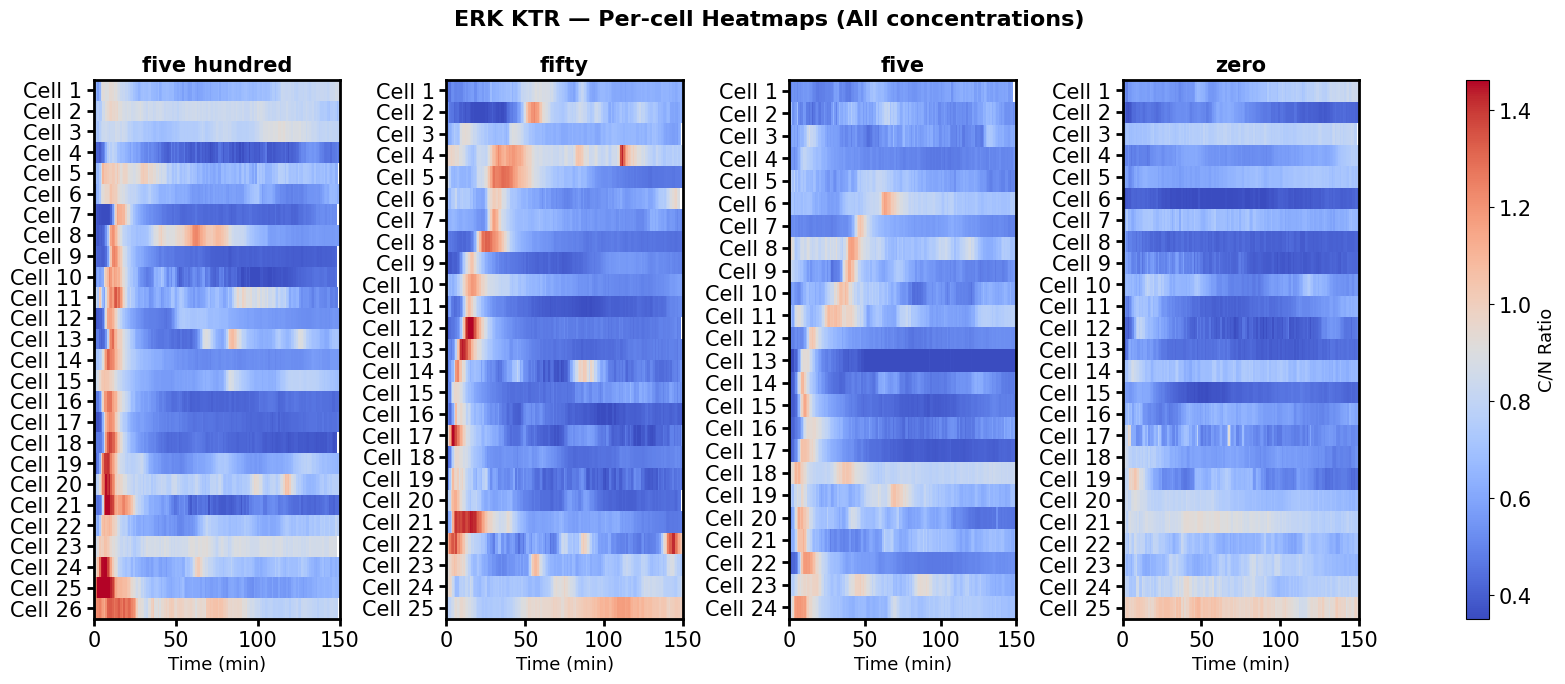

In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

LABEL_FS = 13
TICK_FS  = 15
SPINE_LW = 2.0
TICK_LW  = 2.0
TICK_LEN = 5

def style_ax(ax):
    for spine in ax.spines.values():
        spine.set_linewidth(SPINE_LW)
    ax.tick_params(axis='both', which='major',
                   width=TICK_LW, length=TICK_LEN, labelsize=TICK_FS)

# --- Load raw data, no smoothing ---
df = pd.read_csv('ALL CONC.csv', header=None)
raw_conditions = df.iloc[0].tolist()
data = df.iloc[1:].astype(float).values
conditions = [str(c).split('.')[0].strip() for c in raw_conditions]

def get_group_matrix(conditions, data, group):
    idxs = [i for i, c in enumerate(conditions) if c == group]
    return np.array([data[:, i].astype(float) for i in idxs])

# --- Condition panels, left -> right ---
group_names = ['five hundred', 'fifty', 'five', 'zero']
mats = {g: get_group_matrix(conditions, data, g) for g in group_names}

# --- Manual row orders (1-indexed cell IDs within each condition) ---
#  Paste reordered IDs from the trace-reorder tool here.
#  Defaults below = natural order (1..N).
order_ids = {
    "five hundred": [3,5,10,25,24,9,4,11,13,26,22,2,12,7,14,15,16,8,6,20,21,17,19,18,23,1],
    "fifty": [18,5,10,15,4,12,6,8,17,24,7,21,3,25,11,13,16,22,23,2,1,14,20,9,19],
    "five": [2,23,21,17,8,5,9,6,4,22,18,14,24,10,15,20,19,7,3,16,11,13,1,12],
    "zero": [8,21,1,9,4,18,22,13,20,14,5,24,6,11,15,16,23,3,25,19,10,12,7,17,2],
}

# Convert 1-indexed IDs to 0-indexed positions and reorder rows
sorted_mats = {g: mats[g][[i - 1 for i in order_ids[g]]] for g in group_names}

t    = np.arange(data.shape[0])
vmin = min(np.nanmin(ko_mat), np.nanmin(nt_mat))
vmax = max(np.nanmax(ko_mat), np.nanmax(nt_mat))
# vmin = min(np.nanmin(ko_mat), np.nanmin(nt_mat))
# vmax = 1.5
base_cmap = matplotlib.colormaps['coolwarm'].with_extremes(bad='white')

fig = plt.figure(figsize=(18, 7))
gs = gridspec.GridSpec(1, len(group_names) + 1,
                       width_ratios=[mats[g].shape[0] for g in group_names] + [2.5],
                       wspace=0.55)
axes  = [fig.add_subplot(gs[k]) for k in range(len(group_names))]
ax_cb = fig.add_subplot(gs[len(group_names)])

for ax, g in zip(axes, group_names):
    mat = sorted_mats[g]
    n_cells = mat.shape[0]
    masked  = np.ma.masked_invalid(mat)
    im = ax.imshow(masked,
                   aspect='auto',
                   interpolation='nearest',
                   cmap=base_cmap,
                   vmin=vmin, vmax=vmax,
                   extent=[t[0], t[-1], n_cells + 0.5, 0.5])
    ax.set_xlabel('Time (min)', fontsize=LABEL_FS)
    ax.set_title(g, fontsize=15, fontweight='bold')
    ax.set_yticks(np.arange(1, n_cells + 1))
    ax.set_yticklabels([f'Cell {i+1}' for i in range(n_cells)], fontsize=9)
    ax.set_xlim(t[0], t[-1])
    style_ax(ax)

cbar = fig.colorbar(im, cax=ax_cb)
cbar.set_label('C/N Ratio', fontsize=LABEL_FS)
cbar.ax.tick_params(labelsize=TICK_FS)

fig.suptitle('ERK KTR — Per-cell Heatmaps (All concentrations)',
             fontsize=16, fontweight='bold')
plt.show()
OUTFILE = "ALL heatmap"
fig.savefig(f"{OUTFILE}.pdf", bbox_inches="tight")   # vector, for further editing

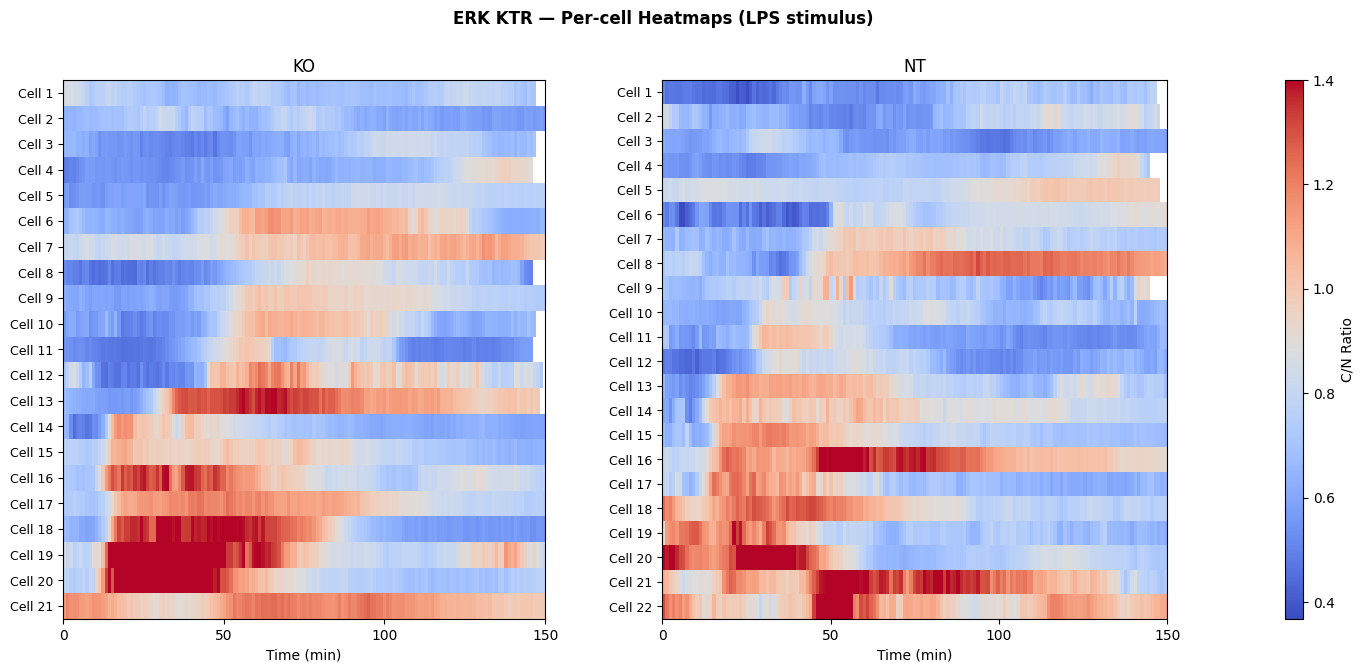

In [ ]:
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
from matplotlib import gridspec

CSV, VMAX = "LPS.csv", 1.4
order = {
    "KO": [18, 10, 14, 16, 12, 8, 9, 20, 13, 15, 19, 21, 17, 4, 7, 6, 2, 5, 3, 1, 11],
    "NT": [20, 21, 12, 18, 17, 19, 9, 8, 22, 7, 15, 11, 14, 2, 3, 1, 4, 13, 5, 10, 6, 16],
}      # 1-indexed IDs from reorder GUI; [] = natural

df   = pd.read_csv(CSV, header=None)
cond = [str(c).split('.')[0].strip() for c in df.iloc[0]]
data = df.iloc[1:].astype(float).values

def mat(g):
    m = np.array([data[:, i] for i, c in enumerate(cond) if c == g])
    o = order.get(g) or list(range(1, len(m) + 1))
    return m[[i - 1 for i in o]]

groups = ["KO", "NT"]
mats = {g: mat(g) for g in groups}
vmin = min(np.nanmin(m) for m in mats.values())
cmap = matplotlib.colormaps["coolwarm"].with_extremes(bad="white")
t = np.arange(data.shape[0])

fig = plt.figure(figsize=(16, 7))
gs  = gridspec.GridSpec(1, 3, width_ratios=[mats["KO"].shape[0], mats["NT"].shape[0], 0.8], wspace=0.35)
for k, g in enumerate(groups):
    ax = fig.add_subplot(gs[k]); n = mats[g].shape[0]
    im = ax.imshow(np.ma.masked_invalid(mats[g]), aspect="auto", interpolation="nearest",
                   cmap=cmap, vmin=vmin, vmax=VMAX, extent=[t[0], t[-1], n + 0.5, 0.5])
    ax.set(title=g, xlabel="Time (min)"); ax.set_yticks(range(1, n + 1))
    ax.set_xticks([0, 50, 100, 150])
    ax.set_yticklabels([f"Cell {i+1}" for i in range(n)], fontsize=9)
cb = fig.colorbar(im, cax=fig.add_subplot(gs[2])); cb.set_label("C/N Ratio")
fig.suptitle("ERK KTR — Per-cell Heatmaps (LPS stimulus)", fontweight="bold")
fig.savefig("lps_heatmap.pdf", bbox_inches="tight"); plt.show()

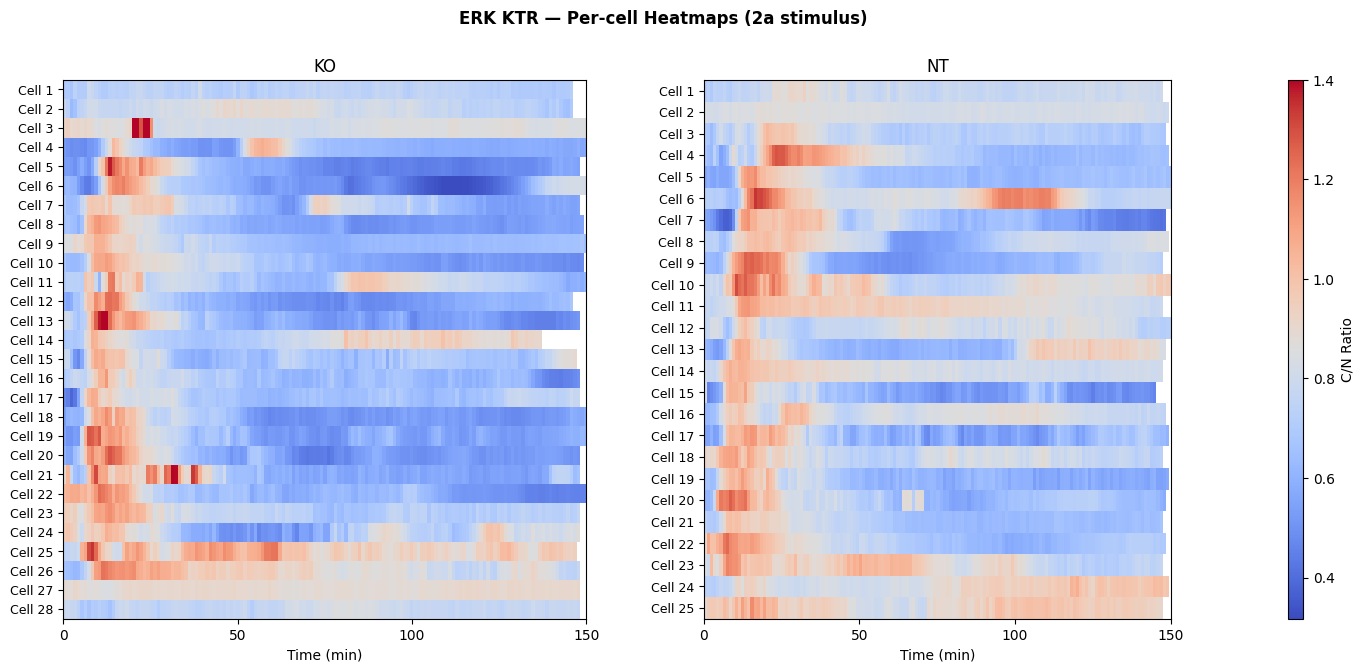

In [5]:
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
from matplotlib import gridspec

CSV, VMAX = "2A.csv", 1.4
order = {
    "KO": [8, 25, 15, 12, 9, 11, 24, 28, 3, 27, 16, 6, 26, 4, 21, 10, 19, 14, 1, 13, 22, 7, 5, 17, 2, 23, 20, 18],
    "NT": [1, 19, 22, 17, 15, 16, 20, 13, 12, 11, 10, 18, 25, 4, 21, 14, 24, 3, 2, 5, 6, 9, 8, 23, 7],
}

df   = pd.read_csv(CSV, header=None)
cond = [str(c).split('.')[0].strip() for c in df.iloc[0]]
data = df.iloc[1:].astype(float).values

def mat(g):
    m = np.array([data[:, i] for i, c in enumerate(cond) if c == g])
    o = order.get(g) or list(range(1, len(m) + 1))
    return m[[i - 1 for i in o]]

groups = ["KO", "NT"]
mats = {g: mat(g) for g in groups}
vmin = min(np.nanmin(m) for m in mats.values())
cmap = matplotlib.colormaps["coolwarm"].with_extremes(bad="white")
t = np.arange(data.shape[0])

fig = plt.figure(figsize=(16, 7))
gs  = gridspec.GridSpec(1, 3, width_ratios=[mats["KO"].shape[0], mats["NT"].shape[0], 0.8], wspace=0.35)
for k, g in enumerate(groups):
    ax = fig.add_subplot(gs[k]); n = mats[g].shape[0]
    im = ax.imshow(np.ma.masked_invalid(mats[g]), aspect="auto", interpolation="nearest",
                   cmap=cmap, vmin=vmin, vmax=VMAX, extent=[t[0], t[-1], n + 0.5, 0.5])
    ax.set(title=g, xlabel="Time (min)"); ax.set_yticks(range(1, n + 1))
    ax.set_xticks([0, 50, 100, 150])
    ax.set_yticklabels([f"Cell {i+1}" for i in range(n)], fontsize=9)
cb = fig.colorbar(im, cax=fig.add_subplot(gs[2])); cb.set_label("C/N Ratio")
fig.suptitle("ERK KTR — Per-cell Heatmaps (2a stimulus)", fontweight="bold")
fig.savefig("2a_heatmap.pdf", bbox_inches="tight"); plt.show()

TRACE PROVENANCE  (condition | genotype | file | abs.col idx | header)
   1K | KO |    1K.csv | col 12 |  KO.12 | onset=10.4f dur(FWHM)=22.4f base=0.679 apex=1.278
   1K | KO |    1K.csv | col 10 |  KO.10 | onset=7.4f dur(FWHM)=19.7f base=0.640 apex=1.167
   1K | KO |    1K.csv | col  1 |   KO.1 | onset=25.4f dur(FWHM)=70.2f base=0.781 apex=1.236
   1K | NT |    1K.csv | col 35 |  NT.16 | onset=9.3f dur(FWHM)=5.9f base=0.905 apex=1.065
   1K | NT |    1K.csv | col 21 |   NT.2 | onset=3.7f dur(FWHM)=9.5f base=0.588 apex=0.947
   1K | NT |    1K.csv | col 28 |   NT.9 | onset=14.0f dur(FWHM)=14.1f base=0.520 apex=1.160
Blank | KO | Blank.csv | col  1 |   KO.1 | (flat) baseline=0.406
Blank | NT | Blank.csv | col 30 |  NT.13 | (flat) baseline=0.510
  LPS | KO |   LPS.csv | col  0 |     KO | onset=12.5f dur(FWHM)=43.0f base=0.752 apex=1.611
  LPS | NT |   LPS.csv | col 23 |   NT.2 | onset=16.1f dur(FWHM)=46.5f base=0.671 apex=1.204
Wrote erk_ktr_example_figure.png and erk_ktr_example_figure.

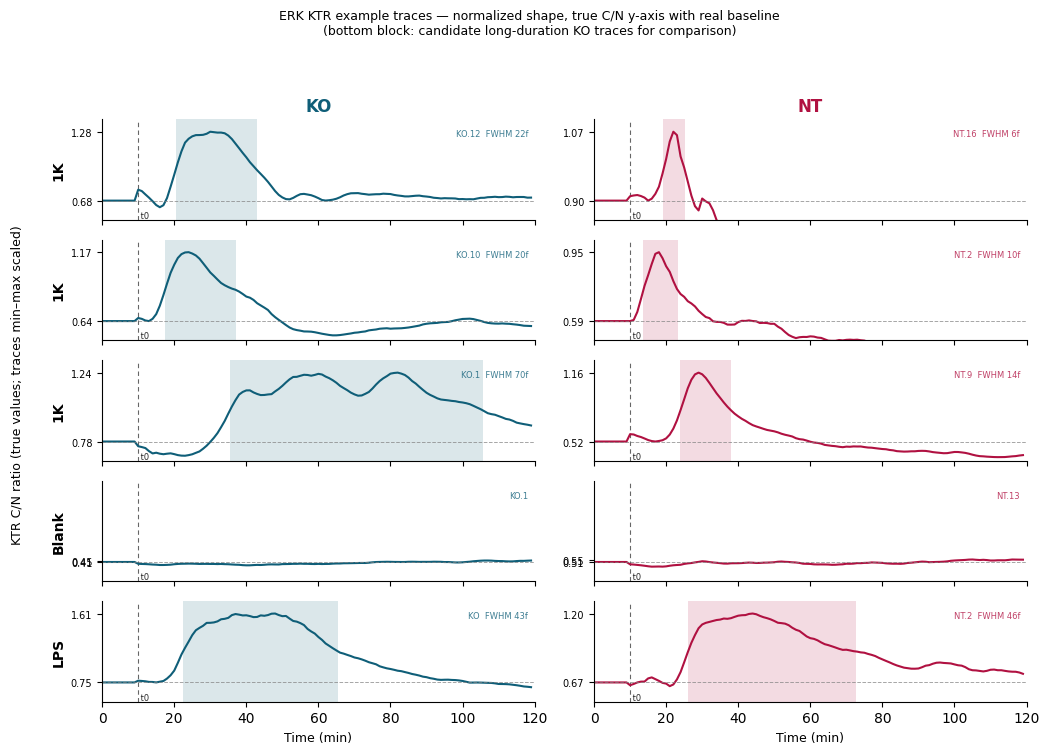

In [2]:

"""
ERK KTR example-trace supplement figure
=======================================
5 x 2 panel figure:
    rows 1-3 : 1K example traces           (KO | NT)
    row  4   : Blank  (no-signal control)  (KO | NT)
    row  5   : LPS    (signal control)     (KO | NT)

Processing matches the analysis pipeline (Erk_KTR_Trace_Analysis):
    - prep_trace: trim NaN edges, linear-interpolate internal NaNs, uniform smooth (win=3)
    - onset / duration / baseline via scipy.find_peaks + peak_widths (NOT first-point averaging)
    - per-trace min-max scaling for display, but the y-axis is relabeled with TRUE C/N values
    - Blank rows are scaled by the same-genotype LPS amplitude so "no signal" reads as flat
      instead of stretched noise.

Everything you are likely to edit is in the CONFIG block below:
    - which cell (CSV column) produces each trace  ->  TRACES
    - normalization/peak params                    ->  SMOOTH_WINDOW, PROMINENCE, ...
    - time window / alignment                      ->  CUT_MIN, UNIFORM_SHIFT, FRAME_INTERVAL_MIN
    - colors, line width, figure size

Run:  python erk_ktr_example_figure.py
Prints a provenance table (file + column label for every plotted trace) and
writes  erk_ktr_example_figure.png / .pdf  next to the script.
"""

import numpy as np
import pandas as pd
from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks, peak_widths
import matplotlib.pyplot as plt

# ============================== CONFIG ======================================= #
# --- file paths (edit if your CSVs live elsewhere) ---
FILES = {"1K": "1K.csv", "Blank": "Blank.csv", "LPS": "LPS.csv"}

# --- pipeline parameters (kept identical to the analysis notebook) ---
SMOOTH_WINDOW     = 6       # uniform_filter1d window
PROMINENCE        = 0.057   # find_peaks prominence
MIN_PEAK_DIST     = 3       # find_peaks distance (frames)
FWHM_REL_HEIGHT   = 0.55     # peak_widths rel_height for FWHM (duration)
FRAME_INTERVAL_MIN = 1.0    # minutes per frame -> x-axis is in minutes

# --- display window / alignment ---
CUT_MIN        = 120        # crop every trace at this many minutes
UNIFORM_SHIFT  = 10         # frames; ONE shift applied to ALL traces.
                            #   Preserves real onset differences (does NOT per-trace align).
                            #   Set to 0 for pure native-time display.

# --- trace selection ----------------------------------------------------------
# genotype : list of ABSOLUTE 0-based column indices in that CSV.
# The provenance table printed at run time resolves each index to its header label
# (e.g. 1K col 35 -> "NT.16") so you can point to the exact cell in a figure legend.
TRACES = {
    "1K":    {"KO": [12, 10, 1],   "NT": [35, 21, 28]},   # 3 example rows per genotype
    "Blank": {"KO": [1],           "NT": [30]},           # 1 no-signal row
    "LPS":   {"KO": [0],           "NT": [23]},           # 1 signal row
}
# Row order in the figure (top -> bottom). Each entry = (condition, row_index_within_condition)
ROW_PLAN = [("1K", 0), ("1K", 1), ("1K", 2), ("Blank", 0), ("LPS", 0)]

# --- KO long-duration candidates (comparison rows) ----------------------------
# Shown UNDERNEATH the 1K rows, in the KO column only (NT axis is blanked).
# These are for choosing a replacement KO trace; set to [] to remove the block.
#   col 7  = KO.7   FWHM 77.6 f   (longest; late onset 30 f)
#   col 1  = KO.1   FWHM 67.9 f
#   col 5  = KO.5   FWHM 41.9 f   (late onset ~50 f)
#   col 12 = KO.12  FWHM 21.2 f   (early onset, fully contained)
KO_CANDIDATES = []

# --- styling ---
KO_COLOR = "#0F5E78"
NT_COLOR = "#B01141"
LINEWIDTH = 1.5
FIGSIZE = (10.5, 7.5)
YLIM = (-0.28, 1.18)
OUTFILE = "erk_ktr_example_figure"   # .png and .pdf written
# ============================================================================ #


# ----------------------------- processing ----------------------------------- #
def prep_trace(raw):
    """Trim NaN edges, interpolate internal NaNs, smooth. Mirrors pipeline prep_trace."""
    valid = np.where(~np.isnan(raw))[0]
    if len(valid) < 10:
        return None
    t = raw[valid[0]:valid[-1] + 1].astype(float).copy()
    nans = np.isnan(t)
    if nans.any():
        x = np.arange(len(t))
        t = np.interp(x, x[~nans], t[~nans])
    if SMOOTH_WINDOW > 1:
        t = uniform_filter1d(t, size=SMOOTH_WINDOW)
    return t


def dominant_peak(t):
    """Return index of the dominant (max-value) find_peaks peak, or None."""
    pks, _ = find_peaks(t, prominence=PROMINENCE, distance=MIN_PEAK_DIST)
    if len(pks) == 0:
        return None
    return int(pks[np.argmax(t[pks])])


def peak_metrics(t, pk):
    """find_peaks-based baseline/onset/duration for a given peak index.
        base   : prominence base (peak_widths rel_height=1.0)  -> the 'true baseline'
        apex   : t[pk]
        onset  : left FWHM edge (wl)   [frames]
        offset : right FWHM edge (wr)  [frames]
        fwhm   : duration (wr - wl)    [frames]
    """
    widths, _, wl, wr = peak_widths(t, [pk], rel_height=FWHM_REL_HEIGHT)
    _, base_h, _, _ = peak_widths(t, [pk], rel_height=1.0)
    return dict(base=float(base_h[0]), apex=float(t[pk]),
                onset=float(wl[0]), offset=float(wr[0]), fwhm=float(widths[0]))


def shift_and_crop(norm):
    """Apply the single UNIFORM_SHIFT (pad zeros at 0 baseline) then crop to CUT frames."""
    if UNIFORM_SHIFT > 0:
        norm = np.concatenate([np.zeros(UNIFORM_SHIFT), norm])
    elif UNIFORM_SHIFT < 0:
        norm = norm[-UNIFORM_SHIFT:]
    return norm[:CUT_FRAMES]


CUT_FRAMES = int(round(CUT_MIN / FRAME_INTERVAL_MIN))


# ----------------------------- load data ------------------------------------ #
dfs = {cond: pd.read_csv(path, header=0) for cond, path in FILES.items()}


def col_label(cond, idx):
    """Resolve an absolute column index to its header label (e.g. 'NT.16')."""
    return str(dfs[cond].columns[idx])


def get_trace(cond, idx):
    return prep_trace(dfs[cond].iloc[:, idx].values.astype(float))


# Pre-compute LPS amplitude reference per genotype (used to scale the flat Blank rows).
lps_ref = {}
for gt in ("KO", "NT"):
    idx = TRACES["LPS"][gt][0]
    t = get_trace("LPS", idx)
    pk = dominant_peak(t)
    m = peak_metrics(t, pk)
    lps_ref[gt] = m["apex"] - m["base"]      # amplitude in true C/N units


def build_panel(cond, gt, idx):
    """Return dict with normalized display trace + TRUE baseline/apex for y-axis labels."""
    t = get_trace(cond, idx)
    pk = dominant_peak(t)

    if cond == "Blank" or pk is None:
        # No real signal: baseline = robust median; scale by same-genotype LPS amplitude
        base = float(np.median(t))
        amp = lps_ref[gt]
        norm = (t - base) / amp
        apex = None                                   # no meaningful apex to print
        top_true = base + np.nanmax(norm) * amp       # true value of the small observed max
        metr = dict(base=base, apex=None, onset=None, offset=None, fwhm=None)
    else:
        m = peak_metrics(t, pk)
        base, apex = m["base"], m["apex"]
        norm = (t - base) / (apex - base)             # min-max to find_peaks baseline
        top_true = apex
        metr = m

    return dict(norm=norm, base=base, apex=apex, top_true=top_true,
                label=col_label(cond, idx), metrics=metr,
                color=KO_COLOR if gt == "KO" else NT_COLOR)


# ----------------------------- provenance ----------------------------------- #
print("=" * 74)
print("TRACE PROVENANCE  (condition | genotype | file | abs.col idx | header)")
print("=" * 74)
panels = {}   # (cond, gt, local_row) -> panel dict
for cond in ("1K", "Blank", "LPS"):
    for gt in ("KO", "NT"):
        for local_row, idx in enumerate(TRACES[cond][gt]):
            p = build_panel(cond, gt, idx)
            panels[(cond, gt, local_row)] = p
            met = p["metrics"]
            extra = (f"onset={met['onset']:.1f}f dur(FWHM)={met['fwhm']:.1f}f "
                     f"base={p['base']:.3f} apex={p['apex']:.3f}"
                     if met["fwhm"] is not None else
                     f"(flat) baseline={p['base']:.3f}")
            print(f"{cond:>5} | {gt} | {FILES[cond]:>9} | col {idx:>2} | "
                  f"{p['label']:>6} | {extra}")
print("=" * 74)


# ----------------------------- figure --------------------------------------- #
# Row layout: the standard ROW_PLAN rows, then (optionally) the KO candidate
# comparison rows underneath the 1K block.
n_rows = len(ROW_PLAN) + len(KO_CANDIDATES)
fig, axes = plt.subplots(n_rows, 2, figsize=FIGSIZE, sharex=True)  # sharey OFF: true y per panel
x_min = np.arange(CUT_FRAMES) * FRAME_INTERVAL_MIN


def draw_panel(ax, p):
    """Draw one trace panel: trace, true baseline, FWHM duration box, t0, true-value ticks."""
    y = shift_and_crop(p["norm"])
    ax.plot(x_min[:len(y)], y, color=p["color"], lw=LINEWIDTH)

    ax.set_xlim(0, CUT_MIN)
    ax.set_ylim(*YLIM)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

    # true baseline line (normalized 0)
    ax.axhline(0, color="grey", lw=0.7, ls="--", alpha=0.7)

    # shaded box spanning the peak's TRUE duration (FWHM onset->offset from find_peaks),
    # positioned in real time (account for the uniform shift). Skipped for flat Blank rows.
    met = p["metrics"]
    if met.get("onset") is not None and met.get("offset") is not None:
        x0 = (met["onset"] + UNIFORM_SHIFT) * FRAME_INTERVAL_MIN
        x1 = (met["offset"] + UNIFORM_SHIFT) * FRAME_INTERVAL_MIN
        ax.axvspan(x0, x1, color=p["color"], alpha=0.15, lw=0, zorder=0)

    # t0: vertical dashed line where REAL data begins.
    # Everything left of it (the UNIFORM_SHIFT lead-in) is padded baseline, not measured.
    t0_min = UNIFORM_SHIFT * FRAME_INTERVAL_MIN
    ax.axvline(t0_min, color="black", lw=0.8, ls=(0, (4, 3)), alpha=0.6, zorder=1)
    ax.text(t0_min, YLIM[0], " t0", ha="left", va="bottom",
            fontsize=6, color="black", alpha=0.85)

    # y-ticks relabeled with TRUE C/N values
    if p["apex"] is not None:
        ax.set_yticks([0, 1])
        ax.set_yticklabels([f"{p['base']:.2f}", f"{p['apex']:.2f}"], fontsize=7)
    else:  # Blank: bottom = true baseline, top = true value of observed max
        top_norm = float(np.nanmax(y))
        ax.set_yticks([0, top_norm])
        ax.set_yticklabels([f"{p['base']:.2f}", f"{p['top_true']:.2f}"], fontsize=7)

    # tiny cell-ID tag (comment out if not wanted on the figure itself)
    label = p["label"]
    if p["metrics"].get("fwhm") is not None:
        label += f"  FWHM {p['metrics']['fwhm']:.0f}f"
    ax.text(0.985, 0.90, label, transform=ax.transAxes,
            ha="right", va="top", fontsize=6, color=p["color"], alpha=0.8)


# --- standard rows (KO | NT) ---
for r, (cond, local_row) in enumerate(ROW_PLAN):
    for c, gt in enumerate(("KO", "NT")):
        draw_panel(axes[r, c], panels[(cond, gt, local_row)])
    axes[r, 0].set_ylabel(cond, fontsize=10, fontweight="bold")

# --- KO long-duration candidate rows (KO column only; NT side blanked) ---
for k, col_idx in enumerate(KO_CANDIDATES):
    r = len(ROW_PLAN) + k
    p = build_panel("1K", "KO", col_idx)
    draw_panel(axes[r, 0], p)
    axes[r, 0].set_ylabel("1K\ncandidate", fontsize=8, fontweight="bold", color=KO_COLOR)
    axes[r, 1].axis("off")   # no NT counterpart for candidate rows

axes[0, 0].set_title("KO", fontsize=12, fontweight="bold", color=KO_COLOR)
axes[0, 1].set_title("NT", fontsize=12, fontweight="bold", color=NT_COLOR)
axes[-1, 0].set_xlabel("Time (min)", fontsize=9)
axes[len(ROW_PLAN) - 1, 1].set_xlabel("Time (min)", fontsize=9)
fig.text(0.005, 0.5, "KTR C/N ratio (true values; traces min–max scaled)",
         va="center", rotation=90, fontsize=9)
fig.suptitle("ERK KTR example traces — normalized shape, true C/N y-axis with real baseline\n"
             "(bottom block: candidate long-duration KO traces for comparison)",
             fontsize=9, y=1.0)

plt.tight_layout(rect=[0.03, 0, 1, 0.96])
fig.savefig(f"{OUTFILE}.png", dpi=200, bbox_inches="tight")
fig.savefig(f"{OUTFILE}.pdf", bbox_inches="tight")   # vector, for further editing
print(f"Wrote {OUTFILE}.png and {OUTFILE}.pdf")